# 🚀 Classification Challenge: Passenger Transportation Analysis (30/100)

Welcome to MSC-AI Consulting! You are working with the Galactic Transportation Initiative (GTI), a client dedicated to safe and efficient passenger transport between planets. Your goal is to predict if a passenger will be transported based on various personal and travel attributes.

GTI has provided you with a preprocessing pipeline (`preprocessor`), which handles all the necessary transformations and encoding of features. Use this pipeline to focus on model comparison, evaluation, and optimization based on different error costs.



# 📄 Dataset Overview
Key features in the dataset include:

- `Age` and `VIP` status of passengers.
- Spending in areas such as `RoomService`, `FoodCourt`, `ShoppingMall`, `Spa`, and `VRDeck`.
- `Cabin` information, split into deck, number, and side.
- `HomePlanet` and `Destination`.
- `CryoSleep` status, which may affect passenger behavior during the journey.
- The **target** variable, `Transported`, indicates whether a passenger was successfully transported (TRUE/FALSE).



# Part A: Initial Model Comparison and Hyperparameter Tuning (12 points)

## Model Selection

Start by comparing two classification models, such as Logistic Regression and K-Nearest Neighbors (KNN). These models will serve as your baseline for understanding general performance on this dataset.

## Hyperparameter Tuning

Perform `RandomizedSearchCV` with 5-fold cross-validation (`cv=5`) to optimize each model. Use two hyperparameters for each model:
- For Logistic Regression, consider parameters such as `C` (regularization strength) and `solver`.
- For K-Nearest Neighbors, consider parameters like `n_neighbors` and `weights`.

Record the best parameters and use the optimized models for further evaluation.

## Performance Metrics

Evaluate both optimized models on the test set using accuracy, precision, recall, F1-score, and AUC-ROC.
Generate ROC-AUC curves for each model and plot them to visualize the trade-offs between true positive and false positive rates.

## Model Comparison

Based on all performance metrics, ROC-AUC, choose the winning model from this initial comparison and save it as `best_model`. 

# Part B: Error Analysis and Threshold Selection for Specific Scenarios (18 points)

Use the `best_model`, optimized model from Part A for threshold selection and error analysis, focusing on GTI’s two specific scenarios:

## Scenario 1: Both False Negatives (FN) and False Positives (FP) are costly

In this scenario, GTI wants a balanced approach that minimizes both FN and FP.
- **Goal**: Find a threshold that achieves a good balance between precision and recall.

## Scenario 2: False Negatives (FN) are more costly than False Positives (FP)

Here, GTI prioritizes minimizing False Negatives.
- **Goal**: Adjust the threshold to achieve higher recall, even if it increases FP.


# Documentation
After completing Part A and Part B, summarize your findings in a brief paragraph:

- For Part A: Explain your model selection and comparison process, highlighting why the chosen model performed best in terms of AUC-ROC. 
- For Part B: Document the thresholds chosen for each scenario, include any trade-offs you encountered when adjusting the threshold, especially in Scenario 2 where FN is prioritized.


In [1]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score, RocCurveDisplay, PrecisionRecallDisplay
import matplotlib.pyplot as plt


# Custom transformer for splitting 'Cabin' feature
class CabinSplitter(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self
    
    def transform(self, X):
        cabin_df = X['Cabin'].fillna('Unknown/0/Unknown').str.split('/', expand=True)
        cabin_df.columns = ['Cabin_Deck', 'Cabin_Num', 'Cabin_Side']
        return cabin_df

#preprocessing pipelines
numeric_features = ['Age', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']
categorical_features = ['HomePlanet', 'CryoSleep', 'Destination', 'VIP']
cabin_feature = ['Cabin'] 

# Num pipeline
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

# Cat pipeline
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Cabin pipeline
cabin_transformer = Pipeline(steps=[
    ('cabin_split', CabinSplitter()),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Full preprocessor pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features),
        ('cabin', cabin_transformer, cabin_feature)
    ])

In [2]:
preprocessor

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer', SimpleImputer()),
                                                 ('scaler', StandardScaler())]),
                                 ['Age', 'RoomService', 'FoodCourt',
                                  'ShoppingMall', 'Spa', 'VRDeck']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['HomePlanet', 'CryoSleep', 'Destination',
                                  'VIP']),
                                ('cabin',
                                 Pipeline(steps=[('cabin_split',
                                                  CabinSplitter()),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Cabin'])])

In [3]:
import pandas as pd
data = pd.read_csv('data/space.csv')
data.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
2,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
3,0010_01,Earth,False,G/1/S,TRAPPIST-1e,48.0,False,719.0,1.0,65.0,0.0,24.0,Reney Baketton,False
4,0012_01,Earth,False,NaN,TRAPPIST-1e,31.0,False,32.0,0.0,876.0,0.0,0.0,Justie Pooles,False


In [4]:
from sklearn.model_selection import train_test_split

target = 'Transported'
X = data.drop(columns=[target, 'Name', 'PassengerId'])
y = data[target]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)



In [5]:
# Double checking there are no duplicates
print(X_train.duplicated().sum())
print(X_test.duplicated().sum())

# Removing duplicates
X_train = X_train.drop_duplicates()
X_test = X_test.drop_duplicates()

# Double checking there are no duplicates
print(X_train.duplicated().sum())
print(X_test.duplicated().sum())

10
2
0
0


In [6]:
# Amend the target variable
y_train = y_train.loc[X_train.index]
y_test = y_test.loc[X_test.index]

In [7]:
# Double checking there are no columns with more than 30% missing values

print(X_train.isnull().mean().sort_values(ascending=False))

CryoSleep       0.024198
VIP             0.024033
ShoppingMall    0.023868
HomePlanet      0.023374
VRDeck          0.023045
Cabin           0.021893
RoomService     0.021893
Age             0.020576
FoodCourt       0.020247
Spa             0.019918
Destination     0.018765
dtype: float64


No columns have more than 30% NaN values 

In [8]:
# Comparing Logistic Regression with KNN
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

# Logistic Regression
log_reg = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression())
])

# KNN
knn = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier())
])

In [9]:
# Using RandomizedSearchCV to find the best hyperparameters
from sklearn.model_selection import RandomizedSearchCV

# Logistic Regression
log_reg_param_grid = {
    'classifier__C': [0.001, 0.01, 0.1, 1, 10, 100, 1000],
    'classifier__solver': ['newton-cg', 'lbfgs', 'liblinear', 'sag', 'saga'],
}

log_reg_search = RandomizedSearchCV(log_reg, log_reg_param_grid, n_iter=20, cv=5, scoring='roc_auc', n_jobs=-1, verbose=0)
log_reg_search.fit(X_train, y_train)

/home/sp1720/miniconda3/envs/dsml2/lib/python3.8/site-packages/sklearn/linear_model/_logistic.py:460: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/sp1720/miniconda3/envs/dsml2/lib/python3.8/site-packages/sklearn/linear_model/_logistic.py:460: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_

RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer()),
                                                                                               ('scaler',
                                                                                                StandardScaler())]),
                                                                               ['Age',
                                                                                'RoomService',
                                                                                'FoodCourt',
                                                                                'ShoppingMall',
                                                                                'Spa',
                                                                                'VRDeck']),
                                                                              ('cat',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='most_frequent')),
                                                                                               ('onehot',
                                                                                                OneHotEncoder(handle_...
                                                                                'Destination',
                                                                                'VIP']),
                                                                              ('cabin',
                                                                               Pipeline(steps=[('cabin_split',
                                                                                                CabinSplitter()),
                                                                                               ('onehot',
                                                                                                OneHotEncoder(handle_unknown='ignore'))]),
                                                                               ['Cabin'])])),
                                             ('classifier',
                                              LogisticRegression())]),
                   n_iter=20, n_jobs=-1,
                   param_distributions={'classifier__C': [0.001, 0.01, 0.1, 1,
                                                          10, 100, 1000],
                                        'classifier__solver': ['newton-cg',
                                                               'lbfgs',
                                                               'liblinear',
                                                               'sag', 'saga']},
                   scoring='roc_auc')

In [10]:
# KNN
knn_param_grid = {
    'classifier__n_neighbors': range(1, 50),
    'classifier__weights': ['uniform', 'distance'],
}

knn_search = RandomizedSearchCV(knn, knn_param_grid, n_iter=20, cv=5, scoring='roc_auc', n_jobs=-1, verbose=0)
knn_search.fit(X_train, y_train)

RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer()),
                                                                                               ('scaler',
                                                                                                StandardScaler())]),
                                                                               ['Age',
                                                                                'RoomService',
                                                                                'FoodCourt',
                                                                                'ShoppingMall',
                                                                                'Spa',
                                                                                'VRDeck']),
                                                                              ('cat',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='most_frequent')),
                                                                                               ('onehot',
                                                                                                OneHotEncoder(handle_...
                                                                               ['HomePlanet',
                                                                                'CryoSleep',
                                                                                'Destination',
                                                                                'VIP']),
                                                                              ('cabin',
                                                                               Pipeline(steps=[('cabin_split',
                                                                                                CabinSplitter()),
                                                                                               ('onehot',
                                                                                                OneHotEncoder(handle_unknown='ignore'))]),
                                                                               ['Cabin'])])),
                                             ('classifier',
                                              KNeighborsClassifier())]),
                   n_iter=20, n_jobs=-1,
                   param_distributions={'classifier__n_neighbors': range(1, 50),
                                        'classifier__weights': ['uniform',
                                                                'distance']},
                   scoring='roc_auc')

In [11]:
# Evaluating the models
from sklearn.metrics import classification_report, roc_auc_score, RocCurveDisplay, PrecisionRecallDisplay

# Logistic Regression
log_reg_pred = log_reg_search.predict(X_test)
log_reg_prob = log_reg_search.predict_proba(X_test)[:, 1]

print('Logistic Regression')
print(classification_report(y_test, log_reg_pred))
print(f'ROC AUC: {roc_auc_score(y_test, log_reg_prob)}')

Logistic Regression
              precision    recall  f1-score   support

       False       0.81      0.77      0.79      1284
        True       0.79      0.82      0.81      1322

    accuracy                           0.80      2606
   macro avg       0.80      0.80      0.80      2606
weighted avg       0.80      0.80      0.80      2606

ROC AUC: 0.8813996069393585


In [12]:
# KNN
knn_pred = knn_search.predict(X_test)
knn_prob = knn_search.predict_proba(X_test)[:, 1]

print('KNN')
print(classification_report(y_test, knn_pred))
print(f'ROC AUC: {roc_auc_score(y_test, knn_prob)}')

KNN
              precision    recall  f1-score   support

       False       0.78      0.83      0.80      1284
        True       0.82      0.77      0.80      1322

    accuracy                           0.80      2606
   macro avg       0.80      0.80      0.80      2606
weighted avg       0.80      0.80      0.80      2606

ROC AUC: 0.8798172315146029


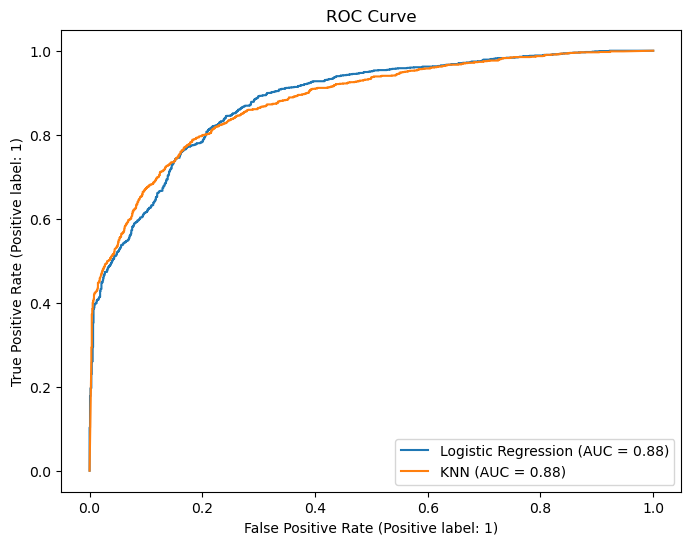

In [13]:
# ROC Curve for both models overlain
fig, ax = plt.subplots(figsize=(8, 6))

log_reg_disp = RocCurveDisplay.from_predictions(y_test, log_reg_prob, ax=ax, name='Logistic Regression')
knn_disp = RocCurveDisplay.from_predictions(y_test, knn_prob, ax=ax, name='KNN')

plt.legend()
plt.title('ROC Curve')
plt.show()


In [14]:
# The best model is the one with the highest ROC AUC score, which is the Logistic Regression model.
best_model = log_reg_search.best_estimator_
best_model

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'RoomService',
                                                   'FoodCourt', 'ShoppingMall',
                                                   'Spa', 'VRDeck']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['HomePlanet', 'CryoSleep',
                                                   'Destination', 'VIP']),
                                                 ('cabin',
                                                  Pipeline(steps=[('cabin_split',
                                                                   CabinSplitter()),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Cabin'])])),
                ('classifier', LogisticRegression(C=100, solver='saga'))])

In [15]:
best_params = log_reg_search.best_params_
best_params

{'classifier__solver': 'saga', 'classifier__C': 100}

In [16]:
best_score = log_reg_search.best_score_
best_score

0.8766050496675284

In [17]:
knn_search.best_score_

0.8737317574121946

The best model is stated above as the Logistic Regression using the above parameters. 

This is because the ROC AUC is slightly higher for the Logistic Regression (0.8814), compared to KNN (0.8797).

### Part B

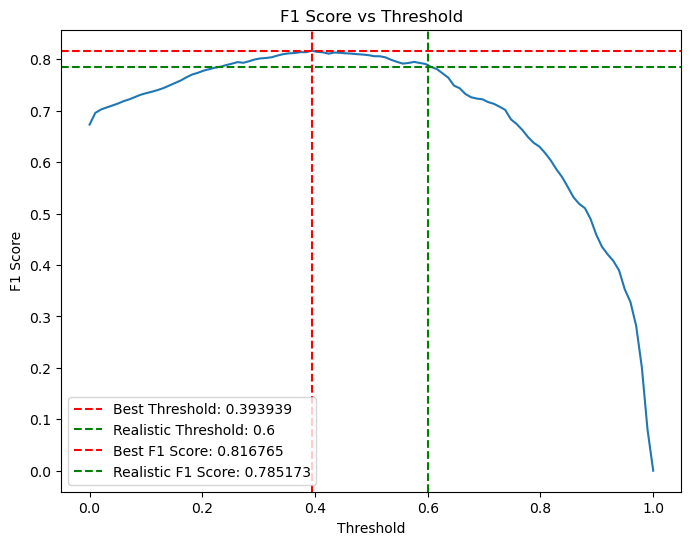

Best Threshold: 0.393939393939394
Best F1 Score: 0.8167648077589191


In [18]:
# Scenario 1: Both FN and FP are costly, therefore F1 score should be maximised
from sklearn.metrics import f1_score
import numpy as np

# Adjusting the threshold to maximise the F1 score
f1_scores = []
thresholds = np.linspace(0, 1, 100)

for threshold in thresholds:
    y_pred = log_reg_prob > threshold
    f1_scores.append(f1_score(y_test, y_pred))

# Best threshold and F1 score as calculated
best_threshold = thresholds[np.argmax(f1_scores)]
best_f1_score = max(f1_scores)

# Realistic threshold score looking at the curve, the F1 score starts to drop at a threshold of 0.6
realistic_threshold = 0.6
realistic_f1_score = f1_scores[int(realistic_threshold*100)]

# Plotting the F1 score against the threshold
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(thresholds, f1_scores)
ax.axvline(best_threshold, color='red', linestyle='--', label = f"Best Threshold: {round(best_threshold,6)}")
ax.axvline(realistic_threshold, color='green', linestyle='--', label = f"Realistic Threshold: {realistic_threshold}")
ax.axhline(best_f1_score, color='red', linestyle='--', label = f"Best F1 Score: {round(best_f1_score,6)}")
ax.axhline(realistic_f1_score, color='green', linestyle='--', label = f"Realistic F1 Score: {round(realistic_f1_score,6)}")
ax.set_xlabel('Threshold')
ax.set_ylabel('F1 Score')
plt.title('F1 Score vs Threshold')
plt.legend()
plt.show()

print(f'Best Threshold: {best_threshold}')
print(f'Best F1 Score: {best_f1_score}')

This analysis can similarly be conducted by looking at where on the precision recall curve that the precision and recall are most similar.

Optimum Recall: 0.800302571860817
Optimum Precision: 0.800302571860817
Optimum Threshold: 0.5340697807933078
Optimum F1 Score: 0.7998486568293606


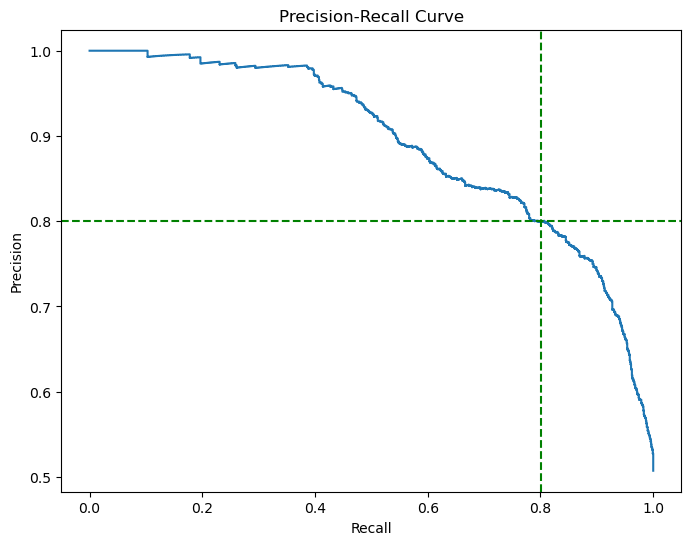

In [55]:
# Plotting a Precision-Recall curve
from sklearn.metrics import precision_recall_curve
fig, ax = plt.subplots(figsize=(8, 6))

precision, recall, thresholds = precision_recall_curve(y_test, log_reg_prob)
pr_display = PrecisionRecallDisplay(precision=precision, recall=recall).plot(ax=ax)

# Finding where precision and recall are most similar
optimum_threshold = thresholds[np.argmin(np.abs(precision - recall))]
optimum_precision = precision[np.argmin(np.abs(precision - recall))]
optimum_recall = recall[np.argmin(np.abs(precision - recall))]
optimum_f1 = f1_score(y_test, log_reg_prob > optimum_threshold)

# Adding the realistic threshold
ax.axvline(optimum_recall, color='green', linestyle='--', label=f'Realistic Threshold: {round(realistic_threshold,6)}')
ax.axhline(optimum_precision, color='green', linestyle='--', label='Minimum Recall = 0.95')

print(f'Optimum Recall: {optimum_recall}')
print(f'Optimum Precision: {optimum_precision}')
print(f'Optimum Threshold: {optimum_threshold}')
print(f'Optimum F1 Score: {optimum_f1}')

plt.title('Precision-Recall Curve')
plt.show()

The Best Threshold score defines if you were to optimise the model for F1 score completely, as this is where the F1 score is highest at 0.82. 

The Realistic Threshold score defines if a more balanced approach were to be taken, so that the highest threshold possible, while maintaining a F1 score similar to the best F1 score would be at about 0.6 threshold for 0.79 F1 score. 

Using the precision recall curve yields similar results, where which value to use would depend on further domain knowledge.

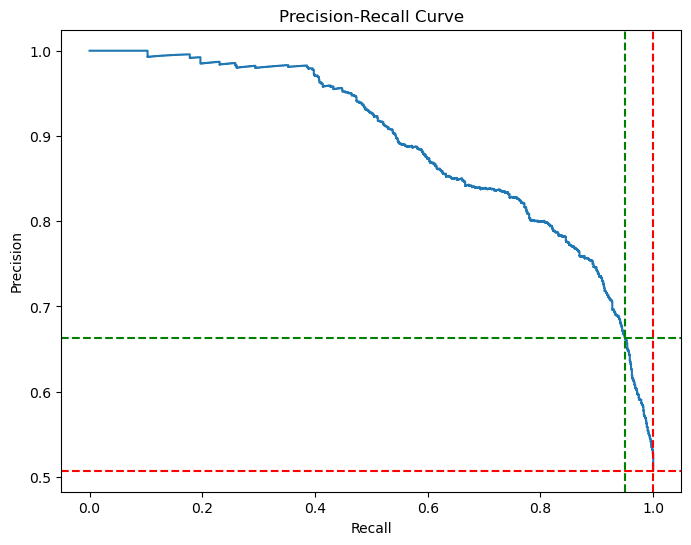

In [ ]:
# Plotting a Precision-Recall curve
from sklearn.metrics import precision_recall_curve
fig, ax = plt.subplots(figsize=(8, 6))

precision, recall, thresholds = precision_recall_curve(y_test, log_reg_prob)
pr_display = PrecisionRecallDisplay(precision=precision, recall=recall).plot(ax=ax)

best_recall = max(recall)
precision_at_best_recall = precision[np.argmax(recall)]

# Realsitic recall
realistic_recall = 0.95
realistic_precision = precision[np.argmin(np.abs(recall - realistic_recall))]

# Adding the best recall
ax.axvline(best_recall, color='red', linestyle='--', label=f'Best Threshold: {round(best_threshold,6)}')
ax.axhline(precision_at_best_recall, color='red', linestyle='--', label=f'Best Recall: {round(best_recall,6)}')

# Adding the realistic threshold
ax.axvline(realistic_recall, color='green', linestyle='--', label=f'Realistic Threshold: {round(realistic_threshold,6)}')
ax.axhline(realistic_precision, color='green', linestyle='--', label='Minimum Recall = 0.95')

plt.title('Precision-Recall Curve')
plt.show()

In [ ]:
# Best and realistic threshold as calculated in precision-recall curve
best_threshold = thresholds[np.argmax(recall)]
realistic_threshold = thresholds[np.argmin(np.abs(recall - realistic_recall))]
realistic_precision = precision[np.argmin(np.abs(recall - realistic_recall))]


print(f'Best Threshold: {best_threshold}')
print(f'Realistic Threshold: {realistic_threshold}')
print(f'Realistic Precision: {realistic_precision}')

Best Threshold: 2.9564489750250435e-15
Realistic Threshold: 0.21244421799219637
Realistic Precision: 0.6627968337730871


The Best Recall would be at 0 threshold, as this is where the recall is highest. 

However, a trade-off might be necessary where a threshold of 0 is not realistic. This is where, using the precision recall curve, a precision of about 0.66 should be used, which is a threshold of about 0.21.

This trade-off can move further down the line, but adjusting this threshold would require more domain knowledge. 